In [1]:
#Imports the libraries used for the classification models and evaluation.
import ipaddress
from urllib.parse import urlsplit
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from torch.utils.data import TensorDataset, DataLoader


In [2]:
#Sets the training parameters and selected device.
batch_size = 256
learning_rate = 0.001
N_Epochs = 30
epsilon = 0.0001
np.random.seed(42)
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)


Device: cpu


In [3]:
#Reads the PhiUSIIL phishing dataset from a local CSV file.
path_data = 'PhiUSIIL_Phishing_URL_Dataset.csv'
PHISH_raw_data = pd.read_csv(path_data, usecols=['URL', 'label'])
print(PHISH_raw_data.shape)
print(PHISH_raw_data.head())


(235795, 2)
                                  URL  label
0    https://www.southbankmosaics.com      1
1            https://www.uni-mainz.de      1
2      https://www.voicefmradio.co.uk      1
3         https://www.sfnmjournal.com      1
4  https://www.rewildingargentina.org      1


In [4]:
#Extracts URL-only features that can also be calculated in website JavaScript.
feature_columns = [
    'url_length', 'domain_length', 'https', 'is_ip',
    'dots', 'hyphens', 'at_signs', 'question_marks',
    'equals', 'digits', 'path_length', 'subdomains',
    'slashes', 'ampersands'
]

def extract_url_features(url):
    url = str(url).strip()
    parts = urlsplit(url)
    hostname = (parts.hostname or '').lower()
    path = parts.path or ''
    try:
        is_ip = int(ipaddress.ip_address(hostname) is not None)
    except ValueError:
        is_ip = 0
    subdomains = max(0, len(hostname.split('.')) - 2) if hostname else 0
    return [
        len(url), len(hostname), int(parts.scheme.lower() == 'https'), is_ip,
        url.count('.'), url.count('-'), url.count('@'), url.count('?'),
        url.count('='), sum(c.isdigit() for c in url), len(path), subdomains,
        url.count('/'), url.count('&')
    ]

#Keeps one record per URL and maps 0=phishing / 1=legitimate to 1=phishing / 0=legitimate.
data = PHISH_raw_data.dropna(subset=['URL', 'label']).copy()
data = data[data['URL'].str.match(r'^https?://', case=False, na=False)]
data = data[data['label'].isin([0, 1])].drop_duplicates(subset='URL').reset_index(drop=True)
X_data = pd.DataFrame([extract_url_features(url) for url in data['URL']], columns=feature_columns)
y = (data['label'] == 0).astype(np.int64).to_numpy()
X = X_data.to_numpy(dtype=np.float32)
print('Rows:', len(data))
print('Features:', feature_columns)
print('Class counts (0=Legitimate, 1=Phishing):', np.bincount(y))
print('Example:', data.loc[0, 'URL'], X[0].tolist())


Rows: 235370
Features: ['url_length', 'domain_length', 'https', 'is_ip', 'dots', 'hyphens', 'at_signs', 'question_marks', 'equals', 'digits', 'path_length', 'subdomains', 'slashes', 'ampersands']
Class counts (0=Legitimate, 1=Phishing): [134850 100520]
Example: https://www.southbankmosaics.com [32.0, 24.0, 1.0, 0.0, 2.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 2.0, 0.0]


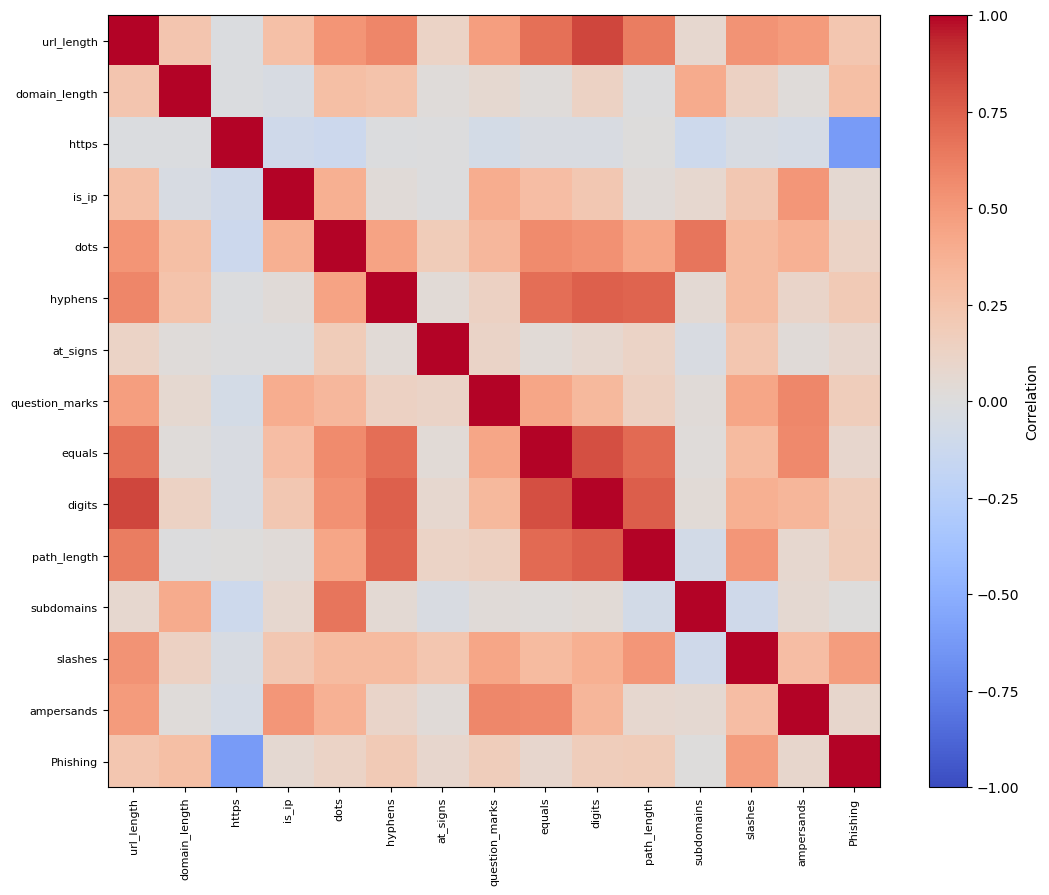

In [5]:
#Displays the correlation matrix for the URL features and phishing label.
corr_data = X_data.copy()
corr_data['Phishing'] = y
correlation = corr_data.corr(numeric_only=True)
plt.figure(figsize=(11, 9))
plt.imshow(correlation, vmin=-1, vmax=1, cmap='coolwarm')
plt.xticks(range(len(correlation)), correlation.columns, rotation=90, fontsize=8)
plt.yticks(range(len(correlation)), correlation.columns, fontsize=8)
plt.colorbar(label='Correlation')
plt.tight_layout()
plt.show()


In [6]:
#Splits the URLs into training, validation, and testing sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)
x_means = torch.tensor(X_train.mean(axis=0, keepdims=True))
x_deviations = torch.tensor(X_train.std(axis=0, keepdims=True) + epsilon)
train_ds = TensorDataset(torch.tensor(X_train), torch.tensor(y_train))
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
print('Training:', len(X_train), 'Validation:', len(X_val), 'Testing:', len(X_test))


Training: 150636 Validation: 37660 Testing: 47074


In [7]:
#Defines the linear classification model used as the baseline.
class LinNet(nn.Module):
    def __init__(self, n_features, means, deviations):
        super().__init__()
        self.register_buffer('means', means)
        self.register_buffer('deviations', deviations)
        self.linear1 = nn.Linear(n_features, 2)

    def forward(self, x):
        x = (x - self.means) / self.deviations
        return self.linear1(x)

In [8]:
#Defines the one-hidden-layer MLP classification model.
class MLP_Net(nn.Module):
    def __init__(self, n_features, means, deviations):
        super().__init__()
        self.register_buffer('means', means)
        self.register_buffer('deviations', deviations)
        self.linear1 = nn.Linear(n_features, 32)
        self.act1 = nn.ReLU()
        self.linear2 = nn.Linear(32, 2)

    def forward(self, x):
        x = (x - self.means) / self.deviations
        x = self.act1(self.linear1(x))
        return self.linear2(x)

In [9]:
#Defines the deep classification model using two hidden layers.
class DL_Net(nn.Module):
    def __init__(self, n_features, means, deviations):
        super().__init__()
        self.register_buffer('means', means)
        self.register_buffer('deviations', deviations)
        self.linear1 = nn.Linear(n_features, 64)
        self.act1 = nn.ReLU()
        self.linear2 = nn.Linear(64, 32)
        self.act2 = nn.ReLU()
        self.linear3 = nn.Linear(32, 2)

    def forward(self, x):
        x = (x - self.means) / self.deviations
        x = self.act1(self.linear1(x))
        x = self.act2(self.linear2(x))
        return self.linear3(x)

In [10]:
#Trains a PyTorch classifier using cross-entropy loss and Adam.
def training_loop(N_Epochs, model, loss_fn, opt):
    history = []
    for epoch in range(N_Epochs):
        model.train()
        losses = []
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            y_pred = model(xb)
            loss = loss_fn(y_pred, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            losses.append(loss.item())
        history.append(np.mean(losses))
        if epoch % 20 == 0 or epoch == N_Epochs - 1:
            print(epoch, 'loss=', round(history[-1], 4))
    return history

#Calculates accuracy, precision, recall, and F1 score.
def print_metrics_function(y_real, y_pred):
    print('Accuracy:', round(accuracy_score(y_real, y_pred), 4))
    print('Precision:', round(precision_score(y_real, y_pred, zero_division=0), 4))
    print('Recall:', round(recall_score(y_real, y_pred, zero_division=0), 4))
    print('F1-measure:', round(f1_score(y_real, y_pred, zero_division=0), 4))

In [11]:
#Trains and compares the linear, MLP, and deep MLP models.
n_features = X_train.shape[1]
models = {
    'Linear': LinNet(n_features, x_means, x_deviations),
    'MLP': MLP_Net(n_features, x_means, x_deviations),
    'Deep MLP': DL_Net(n_features, x_means, x_deviations)
}

results = []
histories = {}
for name, model in models.items():
    print('\nTraining:', name)
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=learning_rate)
    histories[name] = training_loop(N_Epochs, model, nn.CrossEntropyLoss(), opt)
    model.eval()
    with torch.no_grad():
        y_pred = model(torch.tensor(X_val).to(device)).argmax(dim=1).cpu().numpy()
    results.append([name, accuracy_score(y_val, y_pred), precision_score(y_val, y_pred, zero_division=0),
                    recall_score(y_val, y_pred, zero_division=0), f1_score(y_val, y_pred, zero_division=0)])

results_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1'])
results_df = results_df.sort_values('F1', ascending=False).reset_index(drop=True)
results_df.round(4)


Training: Linear
0 loss= 0.529
20 loss= 0.0333
29 loss= 0.0325

Training: MLP
0 loss= 0.1549
20 loss= 0.0222
29 loss= 0.0221

Training: Deep MLP
0 loss= 0.071
20 loss= 0.0217
29 loss= 0.0216


,Model,Accuracy,Precision,Recall,F1
0,Deep MLP,0.9953,0.9985,0.9905,0.9945
1,MLP,0.9952,0.9992,0.9895,0.9943
2,Linear,0.9933,0.9994,0.9848,0.9921


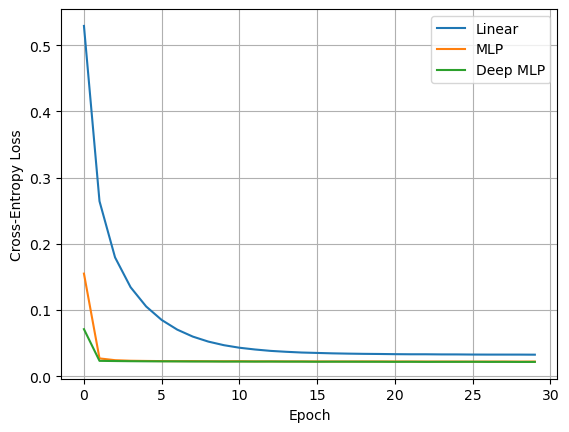

In [12]:
#Plots the training loss for all three models.
for name, values in histories.items():
    plt.plot(values, label=name)
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.legend()
plt.grid(True)
plt.show()

Best model: Deep MLP
Accuracy: 0.9956
Precision: 0.9985
Recall: 0.9911
F1-measure: 0.9948
Confusion matrix (0=Legitimate, 1=Phishing):
[[26940    30]
 [  179 19925]]
              precision    recall  f1-score   support

  Legitimate       0.99      1.00      1.00     26970
    Phishing       1.00      0.99      0.99     20104

    accuracy                           1.00     47074
   macro avg       1.00      0.99      1.00     47074
weighted avg       1.00      1.00      1.00     47074



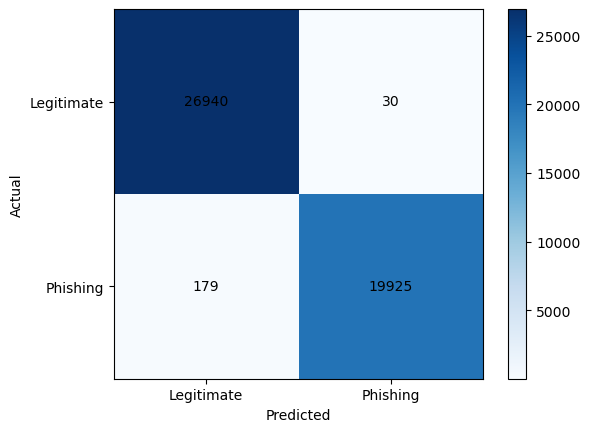

In [13]:
#Tests the model with the best validation F1 score.
best_name = results_df.iloc[0]['Model']
best_model = models[best_name]
best_model.eval()
with torch.no_grad():
    y_pred = best_model(torch.tensor(X_test).to(device)).argmax(dim=1).cpu().numpy()

print('Best model:', best_name)
print_metrics_function(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print('Confusion matrix (0=Legitimate, 1=Phishing):')
print(cm)
print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Phishing'], zero_division=0))
plt.imshow(cm, cmap='Blues')
plt.xticks([0, 1], ['Legitimate', 'Phishing'])
plt.yticks([0, 1], ['Legitimate', 'Phishing'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')
plt.colorbar()
plt.show()

In [14]:
#Exports the best classifier as one ONNX file for GitHub Pages.
best_model = best_model.cpu().eval()
torch.onnx.export(
    best_model,
    torch.zeros(1, n_features, dtype=torch.float32),
    'phishing_model.onnx',
    input_names=['input'],
    output_names=['logits'],
    opset_version=17,
    external_data=False
)
print('Saved phishing_model.onnx')
print('Feature order for the website:', feature_columns)
print('ONNX output: [Legitimate, Phishing] logits')

W1116 14:31:27.606000 8596 site-packages\torch\onnx\_internal\exporter\_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W1116 14:31:28.433000 8596 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::nms
W1116 14:31:28.436000 8596 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::roi_align
W1116 14:31:28.438000 8596 site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::roi_pool
W1116 14:31:28.4390

[torch.onnx] Obtain model graph for `DL_Net([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `DL_Net([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 17).


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Saved phishing_model.onnx
Feature order for the website: ['url_length', 'domain_length', 'https', 'is_ip', 'dots', 'hyphens', 'at_signs', 'question_marks', 'equals', 'digits', 'path_length', 'subdomains', 'slashes', 'ampersands']
ONNX output: [Legitimate, Phishing] logits
